In [1]:
import pandas as pd
import glob
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
files_14 = glob.glob('uber-raw-data-*14.csv')
df = [pd.read_csv(file) for file in files_14]
df_14 = pd.concat(df)

df_15 = pd.read_csv('uber-raw-data-janjune-15.csv')

df_14.rename(columns={'Date/Time': 'date_time'}, inplace=True)
df_15.rename(columns={'Pickup_date': 'date_time'}, inplace=True)

df_14['date_time'] = pd.to_datetime(df_14['date_time'], format='%m/%d/%Y %H:%M:%S')
df_15['date_time'] = pd.to_datetime(df_15['date_time'], format='%Y-%m-%d %H:%M:%S')

df_gl = pd.concat([df_14, df_15])


In [3]:
df_gl['hour'] = df_gl['date_time'].dt.hour
df_gl['day_week'] = df_gl['date_time'].dt.dayofweek
df_gl['month'] = df_gl['date_time'].dt.month
df_gl['year'] = df_gl['date_time'].dt.year
df_gl['year_month'] = df_gl['date_time'].dt.to_period('M')


In [4]:
df_gl['hour'] = df_gl['hour'].astype('Int64')
df_gl['day_week'] = df_gl['day_week'].astype('Int64')
df_gl['month'] = df_gl['month'].astype('Int64')
df_gl['year'] = df_gl['year'].astype('Int64')
df_gl['year_month'] = df_gl['year_month'].astype(str)


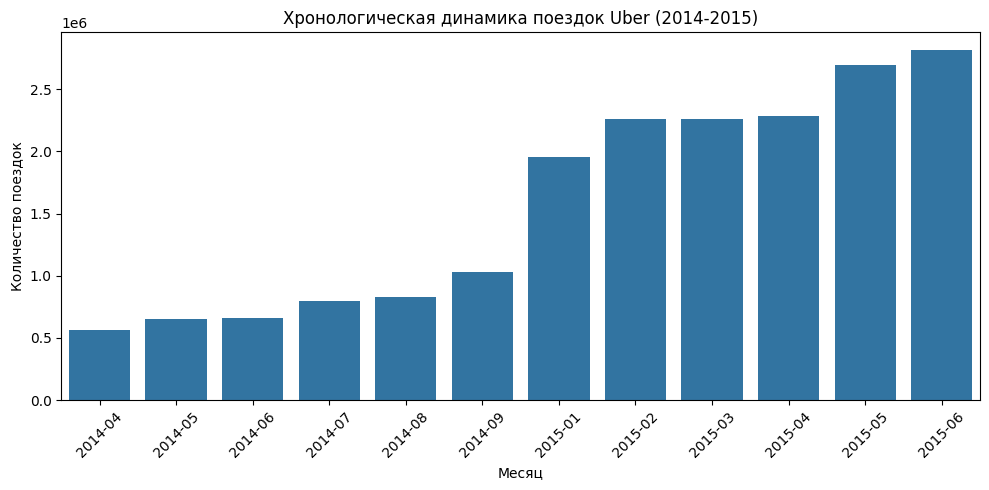

In [5]:
plt.figure(figsize=(10, 5))
df_month = df_gl.groupby(['year_month'])['date_time'].count().reset_index()
sns.barplot(data=df_month, x='year_month', y='date_time')
plt.xticks(rotation=45)
plt.xlabel('Месяц') 
plt.ylabel('Количество поездок')
plt.title('Хронологическая динамика поездок Uber (2014-2015)')
plt.tight_layout()

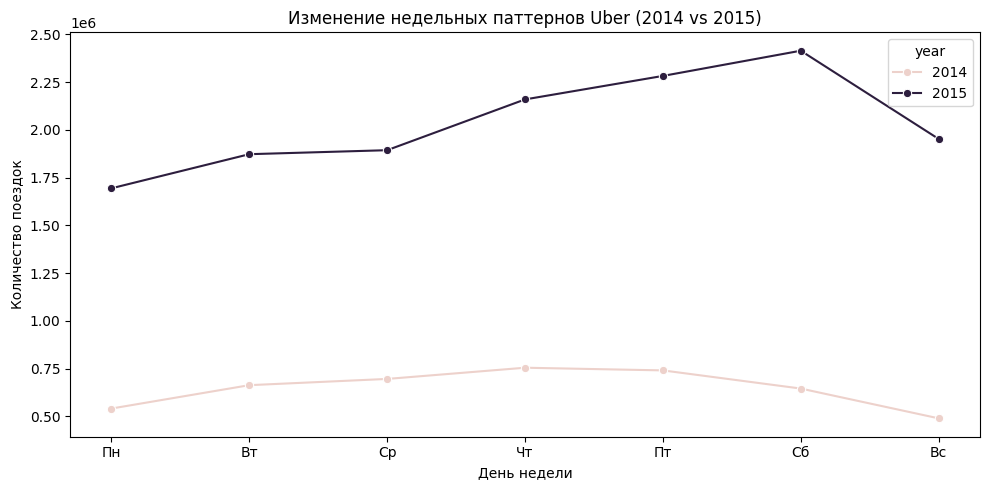

In [6]:
plt.figure(figsize=(10, 5))
df_week = df_gl.groupby(['year', 'day_week'])['date_time'].count().reset_index()
sns.lineplot(data=df_week, x='day_week', y='date_time', hue='year', marker='o')
plt.xticks([0, 1, 2, 3, 4, 5, 6], ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
plt.xlabel('День недели') 
plt.ylabel('Количество поездок')
plt.title('Изменение недельных паттернов Uber (2014 vs 2015)')
plt.tight_layout()